# Student Performance Prediction System
Complete AI/ML Internship Project

## Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

## Load Dataset

In [23]:
df=pd.read_csv('dataset.csv')
df.head()

,StudyHours,Attendance,PreviousMarks,SleepHours,AssignmentsCompleted,FinalScore
0,2,61,87,7,6,76
1,4,68,87,5,4,79
2,7,62,41,5,6,68
3,4,92,78,5,6,84
4,7,74,68,9,7,89


## Dataset Shape

In [24]:
df.shape

(300, 6)

## Dataset Info

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   StudyHours            300 non-null    int64
 1   Attendance            300 non-null    int64
 2   PreviousMarks         300 non-null    int64
 3   SleepHours            300 non-null    int64
 4   AssignmentsCompleted  300 non-null    int64
 5   FinalScore            300 non-null    int64
dtypes: int64(6)
memory usage: 14.2 KB


## Summary

In [26]:
df.describe()

,StudyHours,Attendance,PreviousMarks,SleepHours,AssignmentsCompleted,FinalScore
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,4.560000,80.213333,67.443333,6.993333,6.663333,80.413333
std,2.305961,11.891981,16.543652,1.397545,2.311088,10.921236
min,1.000000,60.000000,40.000000,5.000000,3.000000,56.000000
25%,2.000000,70.000000,53.750000,6.000000,5.000000,72.000000
50%,5.000000,80.000000,67.000000,7.000000,7.000000,79.000000
75%,7.000000,90.000000,82.000000,8.000000,9.000000,89.000000
max,8.000000,100.000000,95.000000,9.000000,10.000000,100.000000


## Missing Values

In [27]:
df.isnull().sum()

StudyHours              0
Attendance              0
PreviousMarks           0
SleepHours              0
AssignmentsCompleted    0
FinalScore              0
dtype: int64

## Duplicates

In [28]:
df.duplicated().sum()

np.int64(0)

## Remove Duplicates

In [31]:
df=df.drop_duplicates()

## Correlation

In [30]:
df.corr(numeric_only=True)

,StudyHours,Attendance,PreviousMarks,SleepHours,AssignmentsCompleted,FinalScore
StudyHours,1.000000,-0.049253,0.006708,0.000125,0.051812,0.622651
Attendance,-0.049253,1.000000,0.017027,0.031479,-0.032182,0.229357
PreviousMarks,0.006708,0.017027,1.000000,-0.021136,-0.020489,0.662965
SleepHours,0.000125,0.031479,-0.021136,1.000000,0.031403,0.126397
AssignmentsCompleted,0.051812,-0.032182,-0.020489,0.031403,1.000000,0.315334
FinalScore,0.622651,0.229357,0.662965,0.126397,0.315334,1.000000


## Histogram

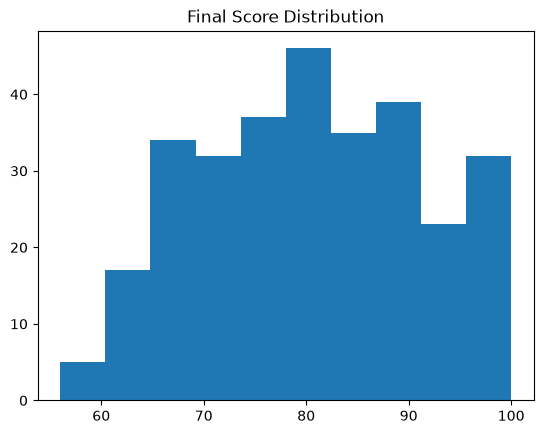

In [32]:
plt.hist(df['FinalScore'])
plt.title('Final Score Distribution')
plt.show()

## Scatter Plot

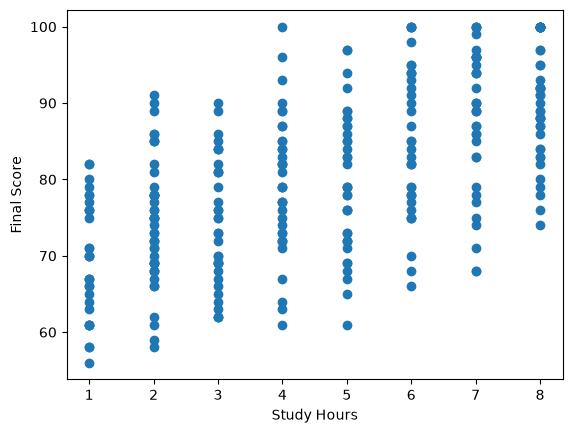

In [33]:
plt.scatter(df['StudyHours'],df['FinalScore'])
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.show()

## Bar Chart

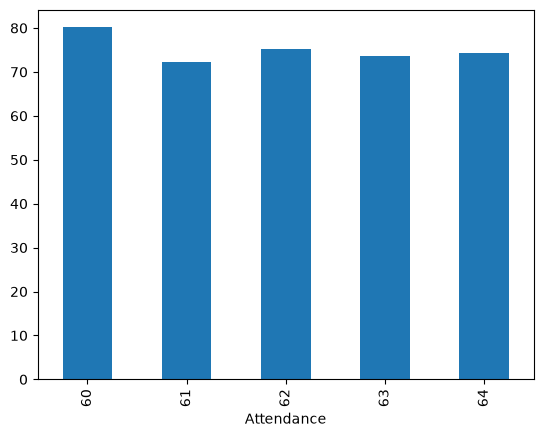

In [34]:
df.groupby('Attendance')['FinalScore'].mean().head().plot(kind='bar')
plt.show()

## Box Plot

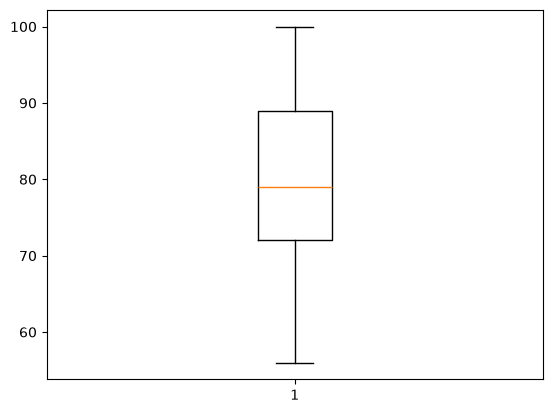

In [35]:
plt.boxplot(df['FinalScore'])
plt.show()

## Feature Selection

In [36]:
X=df[['StudyHours','Attendance','PreviousMarks','SleepHours','AssignmentsCompleted']]
y=df['FinalScore']

## Train Test Split

In [37]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

## Train Model

In [38]:
model=LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[2.94,0.24,0.44,1.01,1.44]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['StudyHours','Attendance','PreviousMarks','SleepHours', 'AssignmentsCompleted']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.451
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


## Prediction

In [39]:
pred=model.predict(X_test)

## Evaluation

In [40]:
print('MAE:',mean_absolute_error(y_test,pred))
print('RMSE:',np.sqrt(mean_squared_error(y_test,pred)))
print('R2 Score:',r2_score(y_test,pred))

MAE: 0.6337432381893933
RMSE: 1.620768497552531
R2 Score: 0.9771005569844583


## Predict New Student

In [43]:
sample = pd.DataFrame({
    "StudyHours": [6],
    "Attendance": [90],
    "PreviousMarks": [80],
    "SleepHours": [7],
    "AssignmentsCompleted": [9]
})

prediction = model.predict(sample)
print("Predicted Final Score:", round(prediction[0], 2))

Predicted Final Score: 95.93


## Save Model

In [44]:
joblib.dump(model,'model.pkl')

['model.pkl']

In [45]:
import joblib
joblib.dump(model, "student_model.pkl")

['student_model.pkl']